# 03 — Propensity Score, Balanceamento e Suporte

Antes de estimar qualquer contraste ajustado, é preciso verificar uma condição básica:

> **Há sobreposição e suporte suficientes nos perfis observados dos dois grupos ao longo dos anos?**

Este notebook responde a essa pergunta com quatro diagnósticos: o escore de propensão, a sobreposição (*overlap*) entre os grupos, o balanceamento das covariáveis e o tamanho efetivo de amostra. Nenhum modelo é ajustado aqui: todos os números são lidos dos artefatos da execução científica original.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# ------------------------------------------------------------
# Raiz do projeto: procurada nos diretórios pais, sem caminho fixo
# ------------------------------------------------------------
cwd = Path.cwd().resolve()
raiz = next(
    (p for p in [cwd, *cwd.parents]
     if (p / "src" / "temporal.py").exists()
     and (p / "docs" / "entrega" / "METADADOS_BASE.md").exists()),
    None,
)
if raiz is None:
    raise FileNotFoundError(f"Raiz do projeto não encontrada a partir de {cwd}")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

venv_projeto = (raiz / ".venv").resolve()
if Path(sys.prefix).resolve() != venv_projeto:
    print(f"Atenção: o kernel não está usando a .venv do projeto ({venv_projeto}).")

from src.visualizacao import CORES_IPT, aplicar_tema_base, configurar_plotly

configurar_plotly()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

ANOS = list(range(2014, 2025))
ESTIMACAO = raiz / "outputs" / "temporal" / "estimacao_v2"
SUPORTE = raiz / "outputs" / "temporal" / "v2_pre_estimacao"
NUISANCE = raiz / "outputs" / "temporal" / "modelos_nuisance"


def num(valor, casas=0):
    """Formata número no padrão brasileiro: 1.234.567,89."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "§").replace(".", ",").replace("§", ".")


def mostrar(fig, titulo, altura=460, largura=950, margem_esquerda=None):
    """Aplica a identidade visual IPT e exibe a figura."""
    aplicar_tema_base(fig, titulo)
    fig.update_layout(width=largura, height=altura, separators=",.")
    if margem_esquerda is not None:
        fig.update_layout(margin_l=margem_esquerda)
    fig.show()


def formatar(tabela, casas=2):
    """Converte uma tabela numérica para texto no padrão brasileiro."""
    return tabela.map(lambda v: "—" if pd.isna(v) else num(v, casas))


def pp(valor, casas=3):
    """Valor em pontos percentuais com sinal de menos tipográfico."""
    return num(valor, casas).replace("-", "−")


print("Raiz do projeto localizada:", raiz.name)

Raiz do projeto localizada: big-data-sinasc-causal-ml


## 1. De onde partimos

- **Notebook 01:** antes de qualquer ajuste, as gestantes que iniciam o pré-natal no 1º–3º mês diferem das que iniciam no 4º–6º mês. São, em média, mais velhas, mais escolarizadas e mais frequentemente casadas.
- **Notebook 02:** definimos o desfecho **Y** (baixo peso), a exposição **T** (início no 1º–3º mês versus 4º–6º mês), as sete covariáveis **X** e as populações **B** (principal) e **C** (sensibilidade, comparador 4º–5º mês).

**Agora:** verificamos se, nos perfis definidos por X, existem gestantes dos dois grupos. Sem isso, nenhum método de ajuste consegue produzir uma comparação confiável. Esses diagnósticos são necessários, mas não demonstram que os grupos sejam comparáveis em fatores não observados.

**Fontes.** Os percentis da distribuição de e(X) e o detalhe do balanceamento por categoria em 2024 vêm do **diagnóstico pré-estimação**. As métricas usadas na interpretação final de suporte, ESS e balanceamento vêm da **estimação final**, com ajuste cruzado em 3 partições. As duas etapas usam o mesmo modelo logístico de propensão.

In [2]:
# Estimação final: uma linha por formulação × ano × especificação × recorte
resultados = pd.read_csv(ESTIMACAO / "resultados_anuais.csv")
nuisance = pd.read_csv(ESTIMACAO / "diagnosticos_nuisance.csv")
recorte = pd.read_csv(ESTIMACAO / "trimming.csv")

# Diagnóstico de suporte feito antes da estimação
suporte_pre = pd.read_csv(SUPORTE / "diagnostico_suporte_v2.csv")
quantis = pd.read_csv(SUPORTE / "quantis_propensity_bracos_v2.csv")
balanco = pd.read_csv(SUPORTE / "balanceamento_v2.csv", dtype={"nivel": str})

# Especificação principal (propensão logística), sem recorte, formulações B e C
c1 = (resultados.query("especificacao == 'C1' and trimming == 'sem_trimming' and formulacao in ['B', 'C']")
      .set_index(["formulacao", "ano"]).sort_index())
prop = (nuisance.query("alvo == 'propensity' and modelo == 'logistica_C1' and formulacao in ['B', 'C']")
        .set_index(["formulacao", "ano"]).sort_index())
pre = suporte_pre[suporte_pre.formulacao.isin(["B", "C"])].set_index(["formulacao", "ano"]).sort_index()

assert len(c1) == len(prop) == len(pre) == 22
assert sorted(c1.loc["B"].index) == sorted(c1.loc["C"].index) == ANOS
assert (c1.status_suporte_09d == pre.status).all()
dif_fora = (c1.fora_005_095_fracao - pre.fora_005_095_fracao).abs().max()
dif_ess = (c1.ess_t0_sobre_n - pre.ess_t0_sobre_n).abs().max()
assert dif_fora < 0.001 and dif_ess < 0.001
print(f"Nota: entre o diagnóstico pré-estimação e a estimação final, a diferença máxima é de {num(100 * dif_fora, 3)} p.p. na fração fora "
      f"de [0,05; 0,95] e de {num(dif_ess, 4)} no ESS/N dos controles.")

Nota: entre o diagnóstico pré-estimação e a estimação final, a diferença máxima é de 0,031 p.p. na fração fora de [0,05; 0,95] e de 0,0001 no ESS/N dos controles.


## 2. O escore de propensão

O **escore de propensão** de uma gestante é

$$
e(X) = P(T = 1 \mid X),
$$

isto é, a **chance estimada de iniciar o pré-natal no 1º–3º mês**, dado o seu perfil X (idade, escolaridade, raça/cor, situação conjugal, paridade, perdas fetais anteriores e UF).

- Um e(X) = 0,90 significa: entre gestantes com esse perfil, cerca de 90% iniciaram cedo.
- O escore **descreve quem tende a iniciar cedo**. Ele não é uma probabilidade de efeito, nem diz nada sobre o peso ao nascer.

O escore tem dois usos neste projeto:

1. **diagnóstico:** se, para algum perfil, e(X) fica muito perto de 0 ou de 1, praticamente só existe um dos grupos naquele perfil, e a comparação ali depende de extrapolação;
2. **ponderação:** no estimador AIPW (notebook 04), cada observação recebe peso inversamente proporcional à chance de pertencer ao próprio grupo. Gestantes "raras" para o seu perfil, como alguém com perfil típico de início precoce que iniciou tarde, recebem mais peso.

## 3. Modelo de propensão principal

A especificação principal é uma **regressão logística com regularização L2 (C = 1)**:

- idade padronizada, com imputação pela mediana e indicador de ausência;
- covariáveis categóricas codificadas como indicadoras (*one-hot*), incluindo a categoria "Ignorado";
- hiperparâmetros fixados antes da estimação, sem busca pelo "melhor" modelo.

A escolha foi consolidada numa comparação feita em 2024, na população histórica A, antes da estimação das formulações B e C. A tabela resume essa comparação.

In [3]:
bench = (pd.read_csv(NUISANCE / "propensity_modelos_2024.csv")
         .set_index("familia").loc[["logistica", "hgb_historico", "extra_trees"]])
assert (bench.n == 2_251_570).all()  # população histórica A, 2024

tabela_bench = pd.DataFrame({
    "AUC": bench.auc,
    "Log loss": bench.log_loss,
    "Erro máximo de calibração": bench.erro_calibracao_maximo,
    "Maior |SMD| após ponderação": bench.max_abs_smd_ponderado,
    "ESS/N dos controles": bench.ess_t0_sobre_n,
}).set_axis(pd.Index(["Regressão logística L2 (C = 1)", "Gradient boosting (HGB)", "Extra Trees"],
                     name="Modelo de propensão, 2024"))
display(formatar(tabela_bench, 3))

,AUC,Log loss,Erro máximo de calibração,Maior |SMD| após ponderação,ESS/N dos controles
"Modelo de propensão, 2024",,,,,
Regressão logística L2 (C = 1),"0,663","0,380","0,004","0,022","0,752"
Gradient boosting (HGB),"0,671","0,378","0,002","0,007","0,756"
Extra Trees,"0,668","0,379","0,014","0,036","0,759"


- Na comparação de 2024 (população A), os três modelos ficam muito próximos: as diferenças aparecem na terceira casa decimal.
- A **logística** foi mantida como referência por ser a mais simples e transparente, com calibração e balanceamento adequados.
- O **HGB** foi mantido como especificação de sensibilidade (C3, seção 8).
- Na comparação disponível de 2024 na população A, o **Extra Trees** não apresentou vantagem clara e apresentou o maior |SMD| pós-ponderação entre os modelos avaliados. Essa comparação não foi repetida em B ou C.

**AUC entre 0,66 e 0,69 é uma boa notícia aqui.** Ela indica que X separa os grupos apenas moderadamente. Se X separasse os grupos perfeitamente (AUC próxima de 1), não haveria gestantes comparáveis nos dois grupos, e a positividade falharia.

## 4. Sobreposição das distribuições (*overlap*)

O gráfico mostra, para cada ano da formulação B, a distribuição de e(X) em cada grupo. As caixas vão do 25º ao 75º percentil, a linha interna é a mediana, e as hastes vão do 1º ao 99º percentil. Os percentis foram calculados sobre todos os registros de cada ano; nenhuma predição individual é carregada aqui.

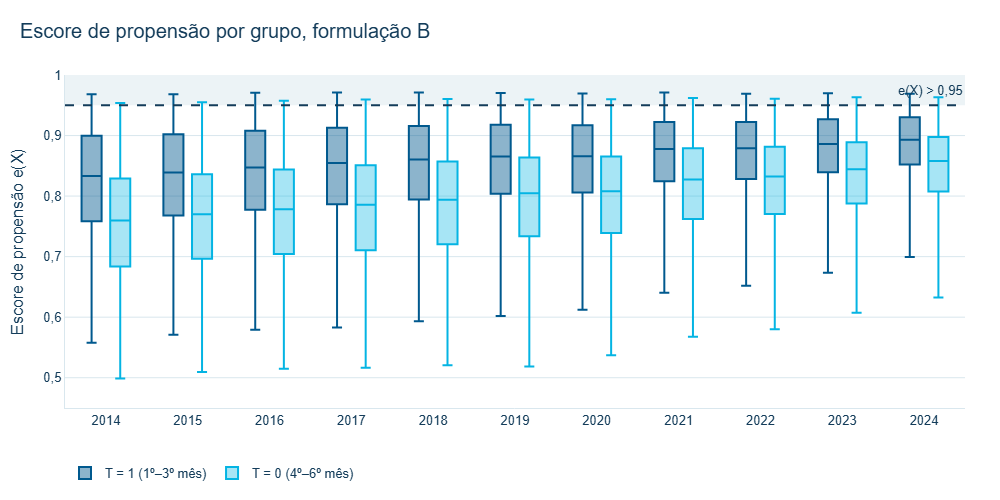

Formulação B, 2014–2024 (estimação final): e(X) varia de 0,195 a 0,988.


In [4]:
qb = quantis[quantis.formulacao == "B"].sort_values("ano")
assert sorted(qb.ano.unique()) == ANOS

fig = go.Figure()
grupos = (("T1", "T = 1 (1º–3º mês)", CORES_IPT["AZUL_PRINCIPAL"], "rgba(0, 89, 142, 0.45)"),
          ("T0", "T = 0 (4º–6º mês)", CORES_IPT["CIANO"], "rgba(4, 180, 227, 0.35)"))
for braco, nome, cor, preenchimento in grupos:
    q = qb[qb.braco == braco]
    fig.add_trace(go.Box(x=q.ano, q1=q.p25, median=q.p50, q3=q.p75, lowerfence=q.p1, upperfence=q.p99,
                         name=nome, marker_color=cor, line=dict(color=cor, width=2),
                         fillcolor=preenchimento, hoverinfo="skip"))
fig.add_hrect(y0=0.95, y1=1.0, fillcolor=CORES_IPT["CINZA_GRADE"], opacity=0.5, line_width=0, layer="below")
fig.add_hline(y=0.95, line_dash="dash", line_color=CORES_IPT["AZUL_ESCURO"])
fig.add_annotation(x=1, xref="paper", y=0.975, text="e(X) > 0,95", showarrow=False, xanchor="right",
                   font=dict(color=CORES_IPT["AZUL_ESCURO"]))
fig.update_layout(boxmode="group", legend=dict(orientation="h", y=-0.15))
fig.update_xaxes(dtick=1)
fig.update_yaxes(title="Escore de propensão e(X)", range=[0.45, 1.0])
mostrar(fig, "Escore de propensão por grupo, formulação B", altura=500, largura=1000)

minimo, maximo = c1.loc["B"].propensity_min.min(), c1.loc["B"].propensity_max.max()
print(f"Formulação B, 2014–2024 (estimação final): e(X) varia de {num(minimo, 3)} a {num(maximo, 3)}.")

- **Há sobreposição ampla em todos os anos.** As caixas dos dois grupos se cruzam, e as hastes cobrem praticamente a mesma faixa.
- **O grupo T = 0 fica deslocado para baixo**, como esperado: quem inicia tarde tem, em média, um perfil associado a menor chance de iniciar cedo.
- **As duas distribuições sobem com o tempo.** Iniciar cedo fica cada vez mais comum (notebook 01), e os escores se concentram perto do limite superior.
- **Não há problema na cauda inferior.** O menor e(X) observado fica perto de 0,2, muito acima de 0,05. Quando há caudas, elas estão **acima de 0,95** e são formadas quase só por gestantes do grupo T = 1.

## 5. Positividade

A **positividade** exige que, para cada perfil X relevante, existam observações **nos dois grupos**. Na prática, isso significa que e(X) não deve ficar muito perto de 0 ou de 1.

Dois limites foram fixados **antes** da estimação:

| Faixa | Uso |
| --- | --- |
| e(X) fora de **[0,05; 0,95]** | sinal de alerta: o ano é **sinalizado** se mais de 10% dos registros estiverem fora dessa faixa |
| e(X) fora de **[0,01; 0,99]** | extremos: indicariam falha grave de suporte |

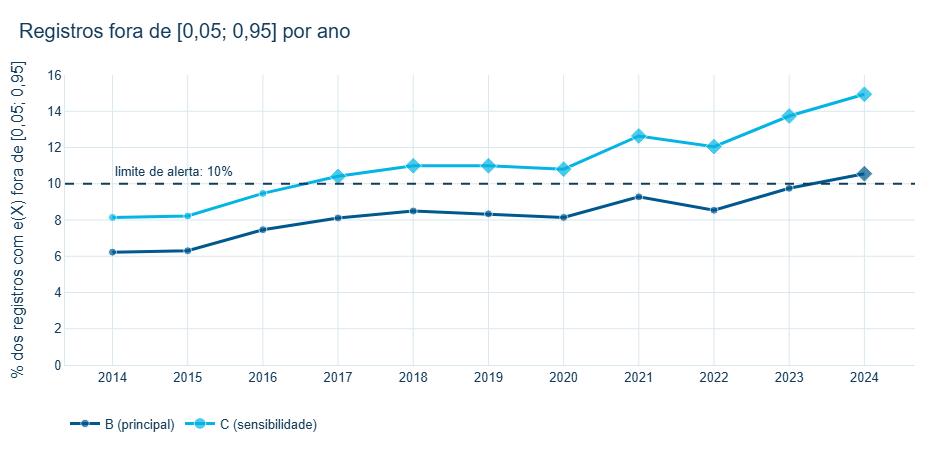

,"B: fora de [0,05; 0,95] (%)",B: situação,"C: fora de [0,05; 0,95] (%)",C: situação,"Fora de [0,01; 0,99], B e C"
Ano,,,,,
2014,"6,22",Aprovado,"8,14",Aprovado,0
2015,"6,30",Aprovado,"8,22",Aprovado,0
2016,"7,47",Aprovado,"9,47",Aprovado,0
2017,"8,12",Aprovado,"10,41",Sinalizado,0
2018,"8,50",Aprovado,"10,99",Sinalizado,0
2019,"8,34",Aprovado,"10,99",Sinalizado,0
2020,"8,14",Aprovado,"10,80",Sinalizado,0
2021,"9,28",Aprovado,"12,64",Sinalizado,0
2022,"8,54",Aprovado,"12,05",Sinalizado,0


B/2024: 232.984 registros fora de [0,05; 0,95], dos quais 223.170 (95,8%) são do grupo T = 1.


In [5]:
SITUACAO = {"APROVADO": "Aprovado", "SINALIZADO": "Sinalizado"}
fig = go.Figure()
for formulacao, nome, cor in (("B", "B (principal)", CORES_IPT["AZUL_PRINCIPAL"]),
                              ("C", "C (sensibilidade)", CORES_IPT["CIANO"])):
    s = c1.loc[formulacao]
    sinalizado = s.status_suporte_09d == "SINALIZADO"
    fig.add_scatter(x=s.index, y=100 * s.fora_005_095_fracao, mode="lines+markers", name=nome,
                    line=dict(color=cor, width=3),
                    marker=dict(size=[13 if v else 8 for v in sinalizado],
                                symbol=["diamond" if v else "circle" for v in sinalizado]))
fig.add_hline(y=10, line_dash="dash", line_color=CORES_IPT["AZUL_ESCURO"])
fig.add_annotation(x=2014, y=10, text="limite de alerta: 10%", showarrow=False, yshift=12, xanchor="left",
                   font=dict(color=CORES_IPT["AZUL_ESCURO"]))
fig.update_xaxes(dtick=1)
fig.update_yaxes(title="% dos registros com e(X) fora de [0,05; 0,95]", range=[0, 16])
fig.update_layout(legend=dict(orientation="h", y=-0.15))
mostrar(fig, "Registros fora de [0,05; 0,95] por ano", altura=450)

positividade = pd.DataFrame({
    "B: fora de [0,05; 0,95] (%)": (100 * c1.loc["B"].fora_005_095_fracao).map(lambda v: num(v, 2)),
    "B: situação": c1.loc["B"].status_suporte_09d.map(SITUACAO),
    "C: fora de [0,05; 0,95] (%)": (100 * c1.loc["C"].fora_005_095_fracao).map(lambda v: num(v, 2)),
    "C: situação": c1.loc["C"].status_suporte_09d.map(SITUACAO),
    "Fora de [0,01; 0,99], B e C": (c1.loc["B"].fora_001_099_n + c1.loc["C"].fora_001_099_n).astype(int),
}).rename_axis("Ano")
assert list(positividade.index[positividade["B: situação"] == "Sinalizado"]) == [2024]
assert list(positividade.index[positividade["C: situação"] == "Sinalizado"]) == list(range(2017, 2025))
assert (c1.fora_001_099_n == 0).all()
display(positividade)

caudas = recorte.query("formulacao == 'B' and ano == 2024 and especificacao == 'C1'").iloc[0]
print(f"B/2024: {num(caudas.n_excluido)} registros fora de [0,05; 0,95], dos quais "
      f"{num(caudas.n_excluido_t1)} ({num(100 * caudas.n_excluido_t1 / caudas.n_excluido, 1)}%) são do grupo T = 1.")

- **B/2024** e **C/2017–2024** (losangos no gráfico) ultrapassam o limite de alerta de 10%. Em C, isso é esperado: o comparador 4º–5º mês é menor, o que aumenta a proporção de tratados e empurra os escores para cima.
- **Nenhum registro fica fora de [0,01; 0,99]** nos resultados finais, em nenhum ano ou formulação.

> **"Sinalizado" não significa que a análise foi invalidada.** Significa que o ano tem caudas mais pesadas e deve ser lido com essa ressalva. Nenhum ano foi removido. O efeito dessas caudas é testado diretamente no notebook 05, com o recorte de suporte em [0,05; 0,95].

*Nota:* dois registros com e(X) ligeiramente acima de 0,99 apareceram apenas no diagnóstico pré-estimação; na estimação final, nenhum registro ficou fora de [0,01; 0,99].

## 6. Balanceamento das covariáveis

A **diferença média padronizada** (SMD) compara a média de cada característica entre T = 1 e T = 0, em unidades de desvio-padrão. Para variáveis categóricas, cada categoria é comparada separadamente. Uma referência usual é |SMD| < 0,1 para considerar uma característica balanceada.

O SMD é calculado duas vezes:

- **antes do ajuste:** nos grupos brutos, como no notebook 01;
- **depois da ponderação:** com os pesos derivados de e(X). Se o modelo de propensão captura bem o mecanismo de seleção, as diferenças observadas devem praticamente desaparecer.

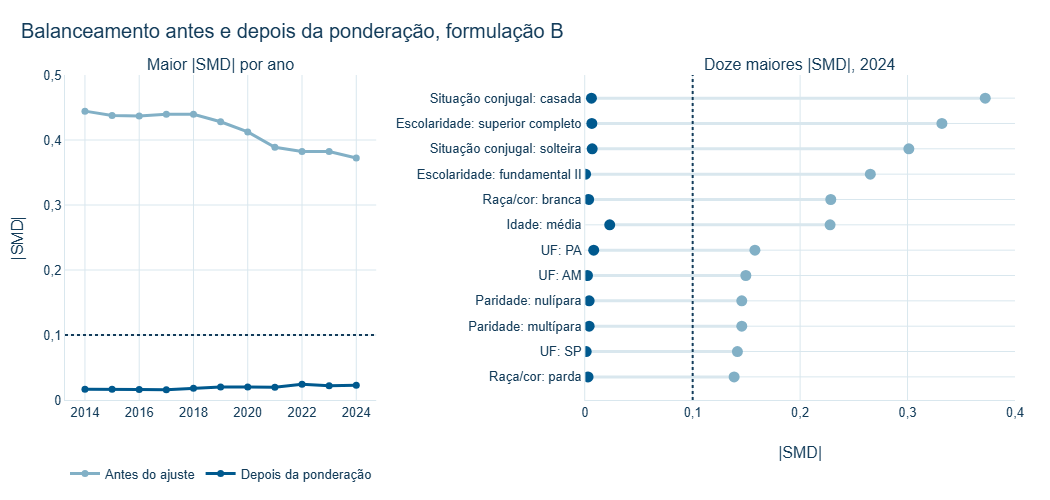

Maior |SMD| antes do ajuste, 2014–2024: 0,37 a 0,44 (sempre situação conjugal: casada).
Maior |SMD| depois da ponderação, 2014–2024: no máximo 0,024.


In [6]:
ROTULOS_X = {
    "IDADEMAE_NUM": ("Idade", {"media": "média", "AUSENTE": "ausente"}),
    "ESCOLARIDADE_MAE": ("Escolaridade", {"0": "sem escolaridade", "1": "fundamental I", "2": "fundamental II",
                                          "3": "médio", "4": "superior incompleto", "5": "superior completo"}),
    "RACA_COR_MAE": ("Raça/cor", {"1": "branca", "2": "preta", "3": "amarela", "4": "parda", "5": "indígena"}),
    "SITUACAO_CONJUGAL": ("Situação conjugal", {"1": "solteira", "2": "casada", "3": "viúva",
                                                "4": "separada", "5": "união estável"}),
    "PARIDADE_CAT": ("Paridade", {"0": "nulípara", "1": "multípara"}),
    "PERDAS_FETAIS_CAT": ("Perdas fetais", {"0": "nenhuma", "1": "uma", "2_OU_MAIS": "duas ou mais"}),
    "UF_RESIDENCIA": ("UF", {"11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA", "16": "AP", "17": "TO",
                             "21": "MA", "22": "PI", "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL",
                             "28": "SE", "29": "BA", "31": "MG", "32": "ES", "33": "RJ", "35": "SP", "41": "PR",
                             "42": "SC", "43": "RS", "50": "MS", "51": "MT", "52": "GO", "53": "DF"}),
}


def rotulo_nivel(variavel, nivel):
    nome, niveis = ROTULOS_X[variavel]
    return f"{nome}: {niveis.get(nivel, 'ignorado' if nivel == 'IGNORADO' else nivel)}"


smd_b = prop.loc["B"]
detalhe = (balanco.query("formulacao == 'B' and ano == 2024")
           .nlargest(12, "abs_smd_bruto")
           .assign(rotulo=lambda t: [rotulo_nivel(v, n) for v, n in zip(t.variavel, t.nivel)]))
assert np.isclose(detalhe.abs_smd_bruto.max(), smd_b.loc[2024, "max_abs_smd_bruto"])
assert (pre.loc["B"].max_abs_smd_bruto_variavel == "SITUACAO_CONJUGAL=2").all()

fig = make_subplots(rows=1, cols=2, column_widths=[0.42, 0.58], horizontal_spacing=0.22,
                    subplot_titles=["Maior |SMD| por ano", "Doze maiores |SMD|, 2024"])
for coluna, nome, cor in (("max_abs_smd_bruto", "Antes do ajuste", CORES_IPT["AZUL_CLARO"]),
                          ("max_abs_smd_ponderado", "Depois da ponderação", CORES_IPT["AZUL_PRINCIPAL"])):
    fig.add_scatter(x=smd_b.index, y=smd_b[coluna], mode="lines+markers", name=nome,
                    line=dict(color=cor, width=3), marker=dict(size=7), row=1, col=1)
for _, linha in detalhe.iterrows():
    fig.add_scatter(x=[linha.abs_smd_ponderado, linha.abs_smd_bruto], y=[linha.rotulo] * 2, mode="lines",
                    line=dict(color=CORES_IPT["CINZA_GRADE"], width=3), showlegend=False, hoverinfo="skip",
                    row=1, col=2)
fig.add_scatter(x=detalhe.abs_smd_bruto, y=detalhe.rotulo, mode="markers", showlegend=False,
                marker=dict(color=CORES_IPT["AZUL_CLARO"], size=11), row=1, col=2)
fig.add_scatter(x=detalhe.abs_smd_ponderado, y=detalhe.rotulo, mode="markers", showlegend=False,
                marker=dict(color=CORES_IPT["AZUL_PRINCIPAL"], size=11), row=1, col=2)
fig.add_hline(y=0.1, line_dash="dot", line_color=CORES_IPT["AZUL_ESCURO"], row=1, col=1)
fig.add_vline(x=0.1, line_dash="dot", line_color=CORES_IPT["AZUL_ESCURO"], row=1, col=2)
fig.update_xaxes(dtick=2, row=1, col=1)
fig.update_yaxes(title="|SMD|", range=[0, 0.5], row=1, col=1)
fig.update_xaxes(title="|SMD|", range=[0, 0.4], row=1, col=2)
fig.update_yaxes(autorange="reversed", row=1, col=2)
fig.update_layout(legend=dict(orientation="h", y=-0.18))
mostrar(fig, "Balanceamento antes e depois da ponderação, formulação B", altura=500, largura=1050)

print(f"Maior |SMD| antes do ajuste, 2014–2024: {num(smd_b.max_abs_smd_bruto.min(), 2)} a "
      f"{num(smd_b.max_abs_smd_bruto.max(), 2)} (sempre situação conjugal: casada).")
print(f"Maior |SMD| depois da ponderação, 2014–2024: no máximo {num(smd_b.max_abs_smd_ponderado.max(), 3)}.")

- **Antes do ajuste, o desequilíbrio é relevante.** Em todos os anos, a maior diferença está na proporção de mães casadas (|SMD| entre 0,37 e 0,44). Escolaridade (superior completo e fundamental II), ser solteira, raça/cor branca e idade também aparecem com |SMD| acima de 0,2 em 2024.
- **Depois da ponderação, todos os |SMD| caem para valores pequenos**, abaixo de 0,025 em todos os anos, bem abaixo da referência de 0,1.

O balanceamento só pode ser verificado para as **características observadas**. Ele não diz nada sobre fatores ausentes do SINASC, como renda, tabagismo ou estado nutricional.

## 7. Tamanho efetivo de amostra (ESS)

Quando as observações recebem pesos diferentes, uma parte da informação se perde: poucas observações com peso alto passam a "valer" mais do que muitas com peso baixo. O **tamanho efetivo de amostra** (*Effective Sample Size*, ESS) responde à pergunta:

> quantas observações com **pesos iguais** carregariam a mesma informação que a amostra ponderada?

A razão **ESS/N** vale 1 quando todos os pesos são iguais e diminui à medida que os pesos ficam desiguais. O indicador mais sensível é o dos **controles** (T = 0): é o grupo menor e o que recebe os maiores pesos.

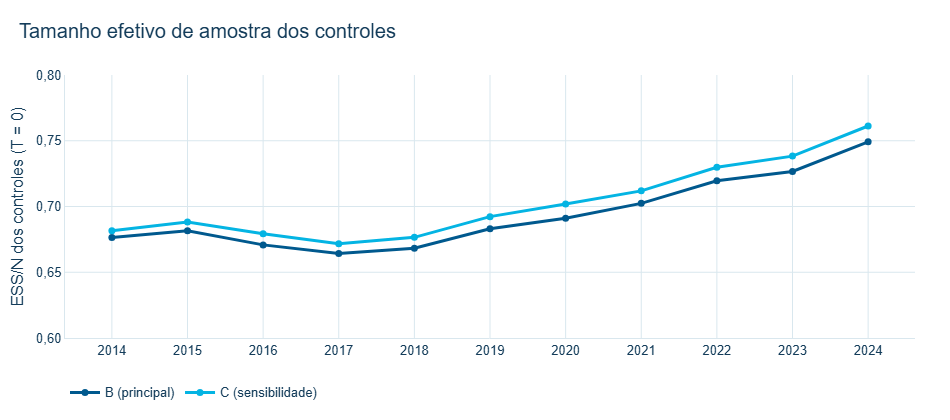

,Controles (T = 0),ESS dos controles,ESS/N
"Ano, formulação B",,,
2014,501.781,339.421,"0,676"
2019,406.953,277.979,"0,683"
2024,265.169,198.668,"0,749"


In [7]:
fig = go.Figure()
for formulacao, nome, cor in (("B", "B (principal)", CORES_IPT["AZUL_PRINCIPAL"]),
                              ("C", "C (sensibilidade)", CORES_IPT["CIANO"])):
    s = c1.loc[formulacao]
    fig.add_scatter(x=s.index, y=s.ess_t0_sobre_n, mode="lines+markers", name=nome,
                    line=dict(color=cor, width=3), marker=dict(size=7))
fig.update_xaxes(dtick=1)
fig.update_yaxes(title="ESS/N dos controles (T = 0)", range=[0.6, 0.8], tickformat=".2f")
fig.update_layout(legend=dict(orientation="h", y=-0.15))
mostrar(fig, "Tamanho efetivo de amostra dos controles", altura=420)

b = c1.loc["B"]
ess = pd.DataFrame({
    "Controles (T = 0)": b.n_t0.map(num),
    "ESS dos controles": b.ess_t0.map(num),
    "ESS/N": b.ess_t0_sobre_n.map(lambda v: num(v, 3)),
}).rename_axis("Ano, formulação B").loc[[2014, 2019, 2024]]
assert (c1.ess_t1_sobre_n > 0.98).all()
display(ess)

- Em B, o ESS/N dos controles fica entre **0,66 e 0,75**. A ponderação "custa" de 25% a 34% da informação dos controles.
- Mesmo assim, o volume efetivo continua muito alto: cerca de **339 mil controles efetivos em 2014 e 199 mil em 2024**.
- O ESS/N dos tratados (T = 1) fica acima de 0,98 em todos os anos.

Há perda de eficiência, mas ela não compromete a análise: nenhum ano depende de um punhado de observações com peso extremo.

## 8. Especificações C1, C2 e C3

O AIPW (notebook 04) usa dois tipos de modelo auxiliar: o **modelo de propensão** e(X), discutido neste notebook, e os **modelos de desfecho** m₀(X) e m₁(X), que estimam o risco de baixo peso em cada grupo. Para verificar se a conclusão depende da escolha desses modelos, a análise é repetida em três especificações:

| Especificação | Propensão e(X) | Desfechos m₀(X) e m₁(X) | Papel |
| --- | --- | --- | --- |
| **C1** | regressão logística | regressões logísticas | **referência** |
| C2 | regressão logística | gradient boosting (HGB) | sensibilidade: desfechos flexíveis |
| C3 | gradient boosting (HGB) | gradient boosting (HGB) | sensibilidade: todos os modelos flexíveis |

Os diagnósticos deste notebook referem-se à propensão logística, usada em C1 e C2. A propensão HGB de C3 tem diagnósticos semelhantes. Nenhum contraste foi comparado aqui: isso é feito nos notebooks 04 e 05.

## 9. Síntese

1. **Ampla sobreposição observada.** Os diagnósticos mostram ampla sobreposição observada das distribuições de e(X) em todos os anos e não indicam falta extrema de suporte na estimação final. O modelo de propensão separa os grupos só moderadamente (AUC entre 0,66 e 0,69).
2. **Existem caudas em alguns anos.** B/2024 e C/2017–2024 têm mais de 10% dos registros com e(X) acima de 0,95, quase todos do grupo T = 1. Esses anos são sinalizados, e não removidos.
3. **Há desequilíbrio antes do ajuste.** O maior |SMD| bruto fica entre 0,37 e 0,44, sempre na situação conjugal.
4. **O ajuste reduz os desequilíbrios observados.** Depois da ponderação, todos os |SMD| ficam abaixo de 0,025, com ESS/N dos controles entre 0,66 e 0,75.
5. **Na estimação final, nenhum registro ficou fora de [0,01; 0,99].**

**Próximo notebook:** como o estimador AIPW com ajuste cruzado combina e(X), m₀(X) e m₁(X) para produzir o contraste ajustado.